# Projeto AeroMotion - análise inicial de sensores

Notebook didático: inspeção, limpeza, variáveis temporais, gráficos e treino dos modelos. Os arquivos finais de modelo são gerados pelo script `src/treinar_modelos.py`.

In [8]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Encontra a pasta do projeto se o notebook abrir pela raiz ou por notebooks/.
RAIZ = Path.cwd()
if not (RAIZ / "dados_sensores_aeromotion.csv").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
from src.data_utils import preparar_dados, SENSORES, FEATURES

ARQUIVO = RAIZ / "dados_sensores_aeromotion.csv"
dados_brutos = pd.read_csv(ARQUIVO)
dados_brutos.head()


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha
0,2026-01-01 00:00:00,TURB-103,Carga_Media,100.2,59.79,9.98,4.41,3006.8,48.96,39.68,2
1,2026-01-01 00:10:00,TURB-104,Carga_Alta,100.5,79.49,3.13,4.50,3487.9,59.76,40.02,0
2,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,NaN,3.51,2382.7,44.97,18.73,0
3,2026-01-01 00:30:00,TURB-103,Carga_Media,100.9,64.56,1.43,4.15,3019.9,53.05,27.36,0
4,2026-01-01 00:40:00,TURB-103,Carga_Alta,101.1,70.80,3.44,4.91,3546.0,63.66,39.36,0


## 1. Inspeção dos dados

Conferimos dimensões, tipos, datas, frequência e ausência por equipamento.

In [9]:
print('Dimensões:', dados_brutos.shape)
print(dados_brutos.dtypes)
print('Ausências por equipamento (%)')
print((dados_brutos.groupby('id_equipamento')[SENSORES].apply(lambda x: x.isna().mean()*100)).round(2))
datas = pd.to_datetime(dados_brutos['timestamp']).sort_values()
print('Intervalo geral mediano (min):', datas.diff().dt.total_seconds().div(60).median())

Dimensões: (12000, 11)
timestamp                     object
id_equipamento                object
modo_operacao                 object
horas_operacao_acumuladas    float64
temperatura_mancal_c         float64
vibracao_rms_mms             float64
pressao_oleo_bar             float64
rotacao_rpm                  float64
emissao_acustica_db          float64
corrente_eletrica_amp        float64
tipo_falha                     int64
dtype: object
Ausências por equipamento (%)
                temperatura_mancal_c  vibracao_rms_mms  pressao_oleo_bar  \
id_equipamento                                                             
TURB-101                        2.79              2.99              2.76   
TURB-102                        3.51              2.75              2.65   
TURB-103                        3.78              3.20              2.87   
TURB-104                        3.57              2.79              2.66   

                rotacao_rpm  emissao_acustica_db  corrente_eletrica_a

## 2. Limpeza e criação de variáveis

Valores muito fora da faixa por falha de sensor são removidos antes da interpolação linear por equipamento. Médias e desvios móveis usam janelas temporais reais de 1 hora e 6 horas.

In [10]:
dados = preparar_dados(ARQUIVO)
print(dados[FEATURES + ['tipo_falha']].isna().sum())
dados.head()

temperatura_mancal_c     0
vibracao_rms_mms         0
pressao_oleo_bar         0
rotacao_rpm              0
emissao_acustica_db      0
corrente_eletrica_amp    0
severidade_dinamica      0
vibracao_media_1h        0
vibracao_desvio_1h       0
temperatura_media_1h     0
temperatura_desvio_1h    0
vibracao_media_6h        0
vibracao_desvio_6h       0
temperatura_media_6h     0
temperatura_desvio_6h    0
tipo_falha               0
dtype: int64


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,severidade_dinamica,vibracao_media_1h,vibracao_desvio_1h,temperatura_media_1h,temperatura_desvio_1h,vibracao_media_6h,vibracao_desvio_6h,temperatura_media_6h,temperatura_desvio_6h
0,2026-01-01 00:00:00,TURB-103,Carga_Media,100.2,59.79,9.98,4.41,3006.8,48.96,39.68,2,0.003319,9.980,0.000000,59.790,0.000000,9.980,0.000000,59.790,0.000000
1,2026-01-01 00:10:00,TURB-104,Carga_Alta,100.5,79.49,3.13,4.50,3487.9,59.76,40.02,0,0.000897,3.130,0.000000,79.490,0.000000,3.130,0.000000,79.490,0.000000
2,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,2.50,3.51,2382.7,44.97,18.73,0,0.001049,2.500,0.000000,57.830,0.000000,2.500,0.000000,57.830,0.000000
3,2026-01-01 00:30:00,TURB-103,Carga_Media,100.9,64.56,1.43,4.15,3019.9,53.05,27.36,0,0.000474,5.705,6.045763,62.175,3.372899,5.705,6.045763,62.175,3.372899
4,2026-01-01 00:40:00,TURB-103,Carga_Alta,101.1,70.80,3.44,4.91,3546.0,63.66,39.36,0,0.000970,4.950,4.470537,65.050,5.521331,4.950,4.470537,65.050,5.521331


## 3. Análise exploratória

Correlação entre sensores e comparação simples dos sensores por regime de operação.

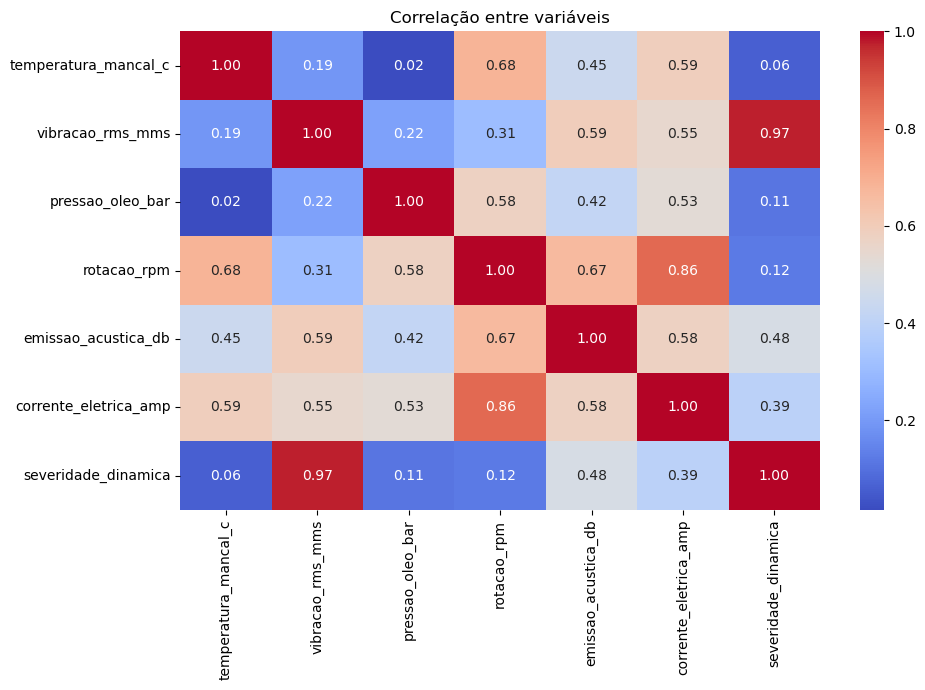

In [11]:
plt.figure(figsize=(10, 7))
sns.heatmap(dados[SENSORES + ['severidade_dinamica']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlação entre variáveis')
plt.tight_layout()
plt.show()

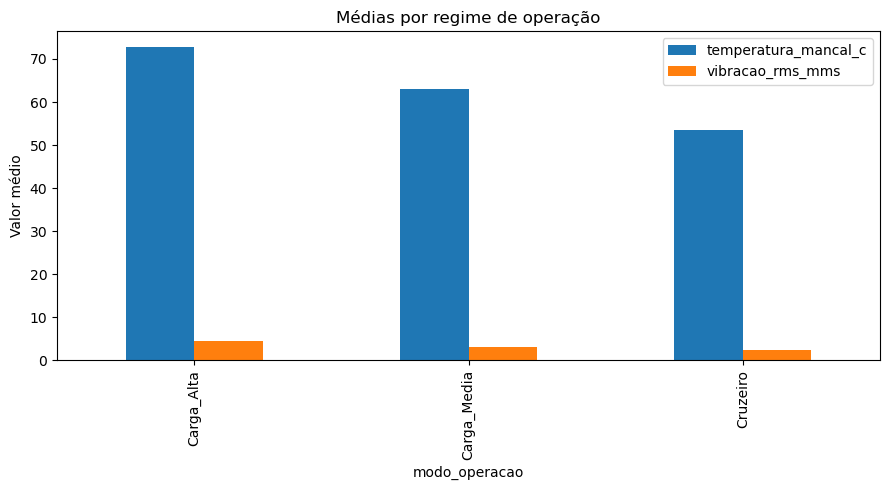

In [12]:
dados.groupby('modo_operacao')[['temperatura_mancal_c', 'vibracao_rms_mms']].mean().plot(kind='bar', figsize=(9, 5))
plt.title('Médias por regime de operação')
plt.ylabel('Valor médio')
plt.tight_layout()
plt.show()

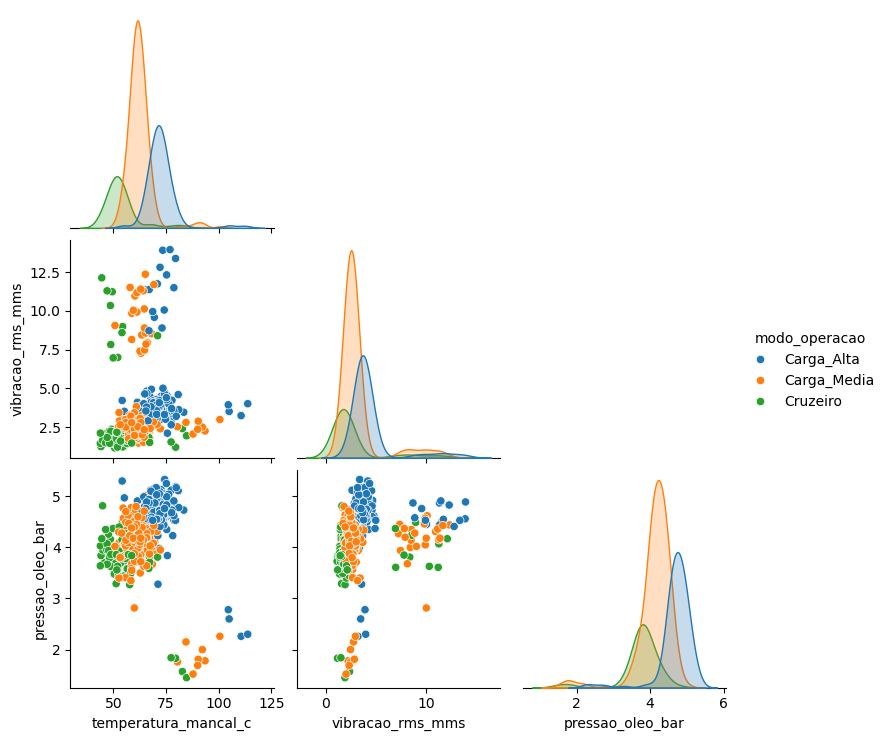

In [13]:
sns.pairplot(dados.sample(min(500, len(dados)), random_state=42), vars=['temperatura_mancal_c','vibracao_rms_mms','pressao_oleo_bar'], hue='modo_operacao', corner=True)
plt.show()

## 4. Modelagem e arquivos exportados

O script executa a divisão temporal 70/30, compara Regressão Logística e Random Forest, ajusta uma grade pequena e salva os modelos e tabelas.

In [14]:
# Execute no terminal a partir da pasta do projeto:
# python src/treinar_modelos.py

## Conclusão

O conjunto possui quatro classes (normal e três falhas) e as classes estão desbalanceadas. A métrica mais importante para manutenção é o recall de cada falha, pois uma falha não detectada pode atrasar a inspeção. Os resultados devem ser interpretados como exercício acadêmico e precisam de validação com dados reais antes de qualquer uso operacional.